In [1]:
from sklearn.datasets import load_iris
import pandas as pd

# Load the Iris dataset
iris = load_iris()

# Convert data into a table
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = iris.target

# Display the first 5 rows
print(df.head())

# Check dataset size
print("Dataset shape:", df.shape)

# Check species names
print("Species:", iris.target_names)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  
Dataset shape: (150, 5)
Species: ['setosa' 'versicolor' 'virginica']


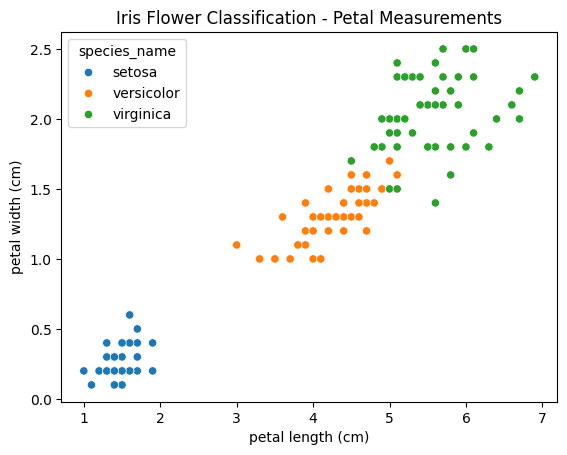

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Add readable species names
df["species_name"] = df["species"].map(
    dict(enumerate(iris.target_names))
)

# Visualize petal measurements by species
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species_name"
)

plt.title("Iris Flower Classification - Petal Measurements")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Select features and target
X = df[iris.feature_names]
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train the model
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

# Predict flower species
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Model accuracy:", round(accuracy * 100, 2), "%")

Training samples: 120
Testing samples: 30
Model accuracy: 100.0 %


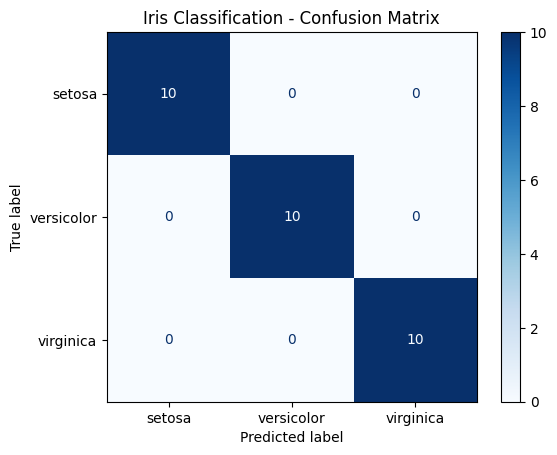

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")
plt.title("Iris Classification - Confusion Matrix")
plt.show()